## Лабораторная работа № 2

## Машинное обучение на больших данных с использованием фреймворка Apache Spark и библиотеки SparkML

### Часть 1

В данной части работы рассмотрены:
* подготовка признаков для решения задачи **регрессии**;
* создание и обучение модели **RandomForestRegressor**;
* подбор гиперпараметров с помощью кросс-валидации;
* оценка качества модели на тестовой выборке.

Датасет Steam Games из лабораторной № 1. Источник данных — подготовленный Parquet `steam_games_cleaned.parquet`. Целевая переменная — `price` (цена игры). Идентификаторы, название, текстовые списки и признаки, непосредственно вычисленные из отзывов, исключены из признаков.

#### Запуск `Spark`-сессии

Подключаем необходимые библиотеки.

In [1]:
import os
import matplotlib.pyplot as plt

from pyspark import SparkConf
from pyspark.sql import SparkSession, DataFrame
from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, Imputer
from pyspark.ml.regression import RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.tuning import CrossValidator, CrossValidatorModel, ParamGridBuilder

Сформируем объект конфигурации для `Apache Spark`, указав параметры локального запуска. При работе в учебном кластере параметры конфигурации можно заменить на используемые в нём.

In [2]:
def create_spark_configuration() -> SparkConf:
    """
    Создает и конфигурирует экземпляр SparkConf для приложения Spark.

    Returns:
        SparkConf: Настроенный экземпляр SparkConf.
    """
    conf = SparkConf()
    conf.setAppName("Lab 2 Steam Random Forest Regression")
    conf.setMaster("local[2]")
    conf.set("spark.driver.memory", "4g")
    conf.set("spark.sql.shuffle.partitions", "8")
    return conf

Создаём сам объект конфигурации.

In [3]:
conf = create_spark_configuration()

Создаём и выводим на экран сессию `Apache Spark`.

In [4]:
spark = SparkSession.builder.config(conf=conf).getOrCreate()
spark.sparkContext.setLogLevel("WARN")
spark

#### Загрузка датасета

Прочитаем подготовленный в первой лабораторной работе Parquet-файл и загрузим его в `Spark DataFrame`.

In [5]:
PARQUET_PATH = "steam_games_cleaned.parquet"

df = spark.read.parquet(PARQUET_PATH)

Выведем несколько строк датасета на экран.

In [6]:
df.show(5, truncate=60)

+-------+----------------------+------------+------------------+----------------+--------+--------+---------------+------------------------+---------------------+-------------------+------------+----------+--------------+-------------------------------------------+---------------------------+---------------------------+------------------------------------------------------------+
| app_id|                  name|release_date|             price|estimated_owners|positive|negative|recommendations|average_playtime_forever|steam_store_available|steam_spy_available|release_year|num_genres|num_categories|                                     genres|                 developers|                 publishers|                                                  categories|
+-------+----------------------+------------+------------------+----------------+--------+--------+---------------+------------------------+---------------------+-------------------+------------+----------+--------------+-------------

Вспомним описание основных столбцов и параметры датасета, проанализированные в первой лабораторной работе.

| Название столбца | Расшифровка | Тип признака |
| ---------------- | ----------- | ------------ |
| `app_id` | Идентификатор игры в Steam | идентификатор, исключён |
| `name` | Название игры | текстовый, исключён |
| `release_date` | Дата выхода игры | текстовый, исключён |
| `price` | Цена игры | целевая переменная |
| `estimated_owners` | Оценка количества владельцев | текстовый диапазон, исключён |
| `positive` | Количество положительных отзывов | признак отзывов, исключён |
| `negative` | Количество отрицательных отзывов | признак отзывов, исключён |
| `recommendations` | Количество рекомендаций | количественный |
| `average_playtime_forever` | Среднее время игры за всё время | количественный |
| `steam_store_available` | Наличие игры в магазине Steam | бинарный |
| `steam_spy_available` | Наличие данных Steam Spy | бинарный |
| `release_year` | Год выпуска игры | количественный |
| `num_genres` | Количество жанров | количественный |
| `num_categories` | Количество категорий | количественный |
| `genres`, `developers`, `publishers`, `categories` | Списки жанров, разработчиков, издателей и категорий | массивы строк, исключены |

Вспомним схему данных.

In [7]:
df.printSchema()

root
 |-- app_id: string (nullable = true)
 |-- name: string (nullable = true)
 |-- release_date: string (nullable = true)
 |-- price: double (nullable = true)
 |-- estimated_owners: string (nullable = true)
 |-- positive: double (nullable = true)
 |-- negative: double (nullable = true)
 |-- recommendations: double (nullable = true)
 |-- average_playtime_forever: double (nullable = true)
 |-- steam_store_available: boolean (nullable = true)
 |-- steam_spy_available: boolean (nullable = true)
 |-- release_year: integer (nullable = true)
 |-- num_genres: double (nullable = true)
 |-- num_categories: double (nullable = true)
 |-- genres: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- developers: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- publishers: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- categories: array (nullable = true)
 |    |-- element: string (containsNull = true)



Вычислим количество строк в датафрейме.

In [8]:
print("Количество строк:", df.count())

Количество строк: 129587


#### Постановка задачи регрессии

Для датасета Steam Games требуется построить модель регрессии **RandomForestRegressor** для оценки цены игры (`price`) по доступным числовым и бинарным признакам.

Идентификаторы, название игры, текстовые списки и признаки, непосредственно отражающие положительные и отрицательные отзывы, в модель не передаются.

Для оценки качества обучения будем использовать метрики **RMSE**, **MAE** и **R²**. RMSE и MAE характеризуют величину ошибки в единицах цены, а R² — долю объяснённой моделью вариации целевой переменной.

#### Подготовка признаков

Определим признаки, которые будут использоваться моделью. Категориальные массивы и текстовые поля не включаем в модель. Логические признаки преобразуем в числовой формат, чтобы их можно было объединить с остальными признаками с помощью `VectorAssembler`.

In [9]:
numeric_candidates = [
    "release_year",
    "num_genres",
    "num_categories",
    "recommendations",
    "average_playtime_forever"
]
binary_candidates = ["steam_store_available", "steam_spy_available"]

available_columns = set(df.columns)
numeric_features = [c for c in numeric_candidates if c in available_columns]
binary_features = [c for c in binary_candidates if c in available_columns]
feature_columns = numeric_features + binary_features

if "price" not in available_columns:
    raise ValueError("В Parquet отсутствует целевая колонка price.")

if not feature_columns:
    raise ValueError("В Parquet не найдены признаки для обучения модели.")

print("Числовые признаки:", numeric_features)
print("Бинарные признаки:", binary_features)

Числовые признаки: ['release_year', 'num_genres', 'num_categories', 'recommendations', 'average_playtime_forever']
Бинарные признаки: ['steam_store_available', 'steam_spy_available']


Приведём целевую переменную и используемые признаки к числовому типу. Некорректные и отсутствующие значения цены удалим. Пропуски в признаках позднее заполним медианными значениями с помощью трансформера `Imputer`.

In [10]:
df = df.withColumn("price", F.col("price").cast("double"))

for feature in numeric_features:
    df = df.withColumn(feature, F.col(feature).cast("double"))
    df = df.withColumn(
        feature,
        F.when(F.isnan(F.col(feature)), None).otherwise(F.col(feature))
    )

for feature in binary_features:
    df = df.withColumn(feature, F.col(feature).cast("double"))

df = df.filter(
    F.col("price").isNotNull()
    & (~F.isnan(F.col("price")))
    & (F.col("price") >= 0)
)

print("Количество строк после очистки:", df.count())
df.select(["price"] + feature_columns).describe().show()

Количество строк после очистки: 129587
+-------+-----------------+------------------+------------------+------------------+------------------+------------------------+---------------------+-------------------+
|summary|            price|      release_year|        num_genres|    num_categories|   recommendations|average_playtime_forever|steam_store_available|steam_spy_available|
+-------+-----------------+------------------+------------------+------------------+------------------+------------------------+---------------------+-------------------+
|  count|           129587|            129587|            129587|            129587|            129587|                  129587|               129587|             129587|
|   mean|9.550480224023621|2022.0152252926605|3.5463433832097357|6.2281401683810875|1220.8366337161808|       82.17552686612083|                  1.0|                1.0|
| stddev|424.8580368852455| 3.442587851175953|2.0748283872062356|5.5323513748469235|22258.836307884652|   

Отделим от датасета случайную выборку объёмом не более 1000 строк и сохраним её в локальный `csv`-набор. Он может понадобиться для следующей лабораторной работы. Поскольку некоторые столбцы исходного датасета имеют тип `array<string>`, перед сохранением преобразуем их в строки.

In [11]:
def save_sample_to_csv(data: DataFrame, file_path: str,
                       sample_size: int = 1000) -> None:
    """
    Сохраняет случайную выборку из DataFrame в CSV-каталог.

    Args:
        data (DataFrame): Исходный Spark DataFrame.
        file_path (str): Путь для сохранения CSV.
        sample_size (int): Максимальный размер выборки.
    """
    sample = data.orderBy(F.rand(seed=11)).limit(sample_size)

    array_columns = [
        "genres", "developers", "publishers", "categories"
    ]
    for column in array_columns:
        if column in sample.columns:
            sample = sample.withColumn(
                column, F.concat_ws(", ", F.col(column))
            )

    (sample.coalesce(1)
           .write.mode("overwrite")
           .option("header", True)
           .csv(file_path))

    print(f"CSV-файл сохранён в каталоге: {file_path}")

Определяем путь для сохранения `csv`-файла и сохраняем выборку.

In [12]:
csv_path = "steam_games_lab2_sample.csv"

save_sample_to_csv(
    data=df,
    file_path=csv_path,
    sample_size=1000
)

CSV-файл сохранён в каталоге: steam_games_lab2_sample.csv


Разделим датасет на обучающую и тестовую выборки в соотношении 80 к 20. Фиксируем `seed`, чтобы разбиение можно было воспроизвести.

In [13]:
train_df, test_df = df.randomSplit([0.8, 0.2], seed=11)

train_df = train_df.cache()
test_df = test_df.cache()

print(f"Train dataset size: {train_df.count()}")
print(f"Test dataset size: {test_df.count()}")

Train dataset size: 103369
Test dataset size: 26218


#### Создание ML-конвейера

Для заполнения пропусков используем `Imputer` со стратегией `median`. Затем `VectorAssembler` объединит подготовленные признаки в единый вектор `features`, который будет передан модели `RandomForestRegressor`.

В отличие от линейной регрессии, для случайного леса не требуется предварительное масштабирование числовых признаков.

In [14]:
imputed_features = [f"{feature}_imputed" for feature in feature_columns]

imputer = Imputer(
    inputCols=feature_columns,
    outputCols=imputed_features,
    strategy="median"
)

assembler = VectorAssembler(
    inputCols=imputed_features,
    outputCol="features",
    handleInvalid="skip"
)

random_forest = RandomForestRegressor(
    featuresCol="features",
    labelCol="price",
    predictionCol="prediction",
    seed=11
)

pipeline = Pipeline(stages=[
    imputer,
    assembler,
    random_forest
])

Выведем описание созданного конвейера.

In [15]:
pipeline

Pipeline_e8da85c455e7

#### Обучение модели

Выполним **подбор гиперпараметров** модели `RandomForestRegressor` с помощью кросс-валидации на сетке.

В качестве настраиваемых гиперпараметров рассмотрим максимальную глубину деревьев (`maxDepth`) и количество деревьев в ансамбле (`numTrees`).

Создадим сетку параметров для кросс-валидации, используя объект `RandomForestRegressor` из конвейера.

In [16]:
param_grid = (
    ParamGridBuilder()
    .addGrid(random_forest.maxDepth, [5, 10])
    .addGrid(random_forest.numTrees, [50, 100])
    .build()
)

Создадим экземпляр `RegressionEvaluator` для оценки качества моделей по метрике `RMSE`.

In [17]:
cv_evaluator = RegressionEvaluator(
    labelCol="price",
    predictionCol="prediction",
    metricName="rmse"
)

Создадим объект `CrossValidator`. Для кросс-валидации используем 3 фолда.

In [18]:
cross_validator = CrossValidator(
    estimator=pipeline,
    estimatorParamMaps=param_grid,
    evaluator=cv_evaluator,
    numFolds=3,
    parallelism=2,
    seed=11
)

Обучаем конвейер с использованием кросс-валидации. В результате будет выбрана модель с наименьшим значением RMSE на проверочных фолдах.

In [19]:
cv_model = cross_validator.fit(train_df)

Выведем параметры **лучшей** модели, определённой в ходе кросс-валидации.

In [20]:
def get_best_model_params(cv_model: CrossValidatorModel) -> dict:
    """
    Получает параметры лучшей модели RandomForestRegressor.
    """
    best_model = cv_model.bestModel
    forest_model = best_model.stages[-1]

    return {
        "maxDepth": forest_model.getMaxDepth(),
        "numTrees": forest_model.getNumTrees,
        "featureSubsetStrategy": forest_model.getFeatureSubsetStrategy()
    }

In [21]:
for key, value in get_best_model_params(cv_model=cv_model).items():
    print(f"{key}: {value}")

maxDepth: 5
numTrees: 100
featureSubsetStrategy: auto


#### Анализ важности признаков

Случайный лес позволяет оценить относительную важность каждого признака. Визуализируем полученные значения: чем выше значение важности, тем больший вклад признак вносит в предсказания модели.

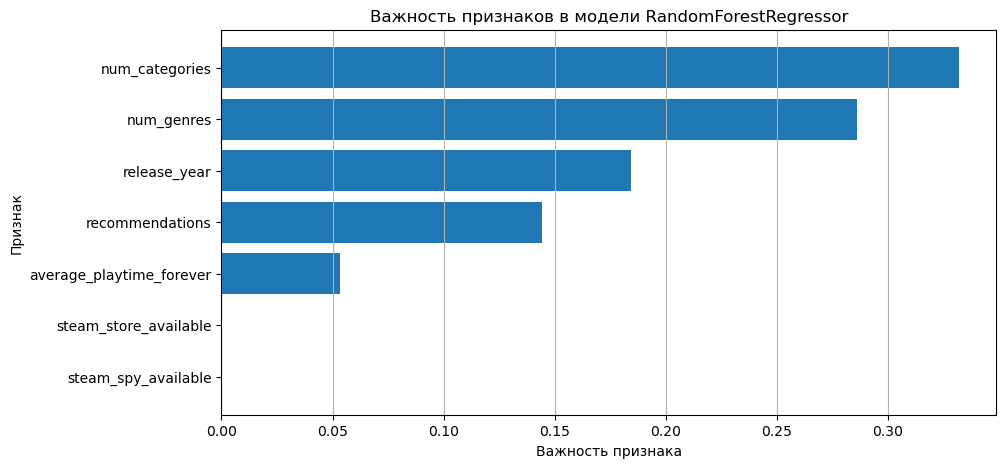

In [22]:
best_forest_model = cv_model.bestModel.stages[-1]
importances = best_forest_model.featureImportances.toArray()

importance_pairs = sorted(
    zip(feature_columns, importances),
    key=lambda item: item[1],
    reverse=True
)

importance_names = [item[0] for item in importance_pairs]
importance_values = [item[1] for item in importance_pairs]

plt.figure(figsize=(10, 5))
plt.barh(importance_names[::-1], importance_values[::-1])
plt.xlabel("Важность признака")
plt.ylabel("Признак")
plt.title("Важность признаков в модели RandomForestRegressor")
plt.grid(axis="x")
plt.show()

#### Проверка обобщающей способности модели

Выполним предсказания на тестовой выборке. Перегруппируем колонки датафрейма, переставив столбец с фактической ценой в конец, чтобы его значения было удобно сравнивать с предсказанными.

In [23]:
test_df_predictions = cv_model.transform(test_df)

right_columns_order = [
    column for column in test_df_predictions.columns
    if column != "price"
]
right_columns_order.append("price")

test_df_predictions = test_df_predictions.select(*right_columns_order)
test_df_predictions.select("prediction", "price").show(10)

+------------------+------------------+
|        prediction|             price|
+------------------+------------------+
| 6.161616625850536|13.989999771118164|
|  6.56309663578602|               0.0|
|10.891927554483043|11.989999771118164|
| 5.942394027360794|0.9900000095367432|
| 6.712396082293634|14.989999771118164|
|6.0975640927206385|1.9900000095367432|
| 9.735542674445574|19.989999771118164|
|6.0975640927206385|               0.0|
| 6.567091627537232|              9.25|
| 6.931948363801347| 4.989999771118164|
+------------------+------------------+
only showing top 10 rows



Создадим функцию оценки модели: расчёта значения выбранной метрики для датафрейма с предсказаниями.

In [24]:
def evaluate_model(data: DataFrame, metric_name: str) -> float:
    """
    Оценивает модель с использованием указанной метрики.

    Args:
        data (DataFrame): DataFrame с предсказаниями и фактическими значениями.
        metric_name (str): Название метрики (например, rmse, mae или r2).

    Returns:
        float: Значение выбранной метрики.
    """
    evaluator = RegressionEvaluator(
        labelCol="price",
        predictionCol="prediction",
        metricName=metric_name
    )
    return evaluator.evaluate(data)

Оценим модель на тестовой выборке по метрикам `RMSE`, `MAE` и `R²`.

In [25]:
test_rmse = evaluate_model(test_df_predictions, "rmse")
test_mae = evaluate_model(test_df_predictions, "mae")
test_r2 = evaluate_model(test_df_predictions, "r2")

print(f"RMSE on test data: {test_rmse:.4f}")
print(f"MAE on test data:  {test_mae:.4f}")
print(f"R^2 on test data:  {test_r2:.4f}")

RMSE on test data: 20.5427
MAE on test data:  7.6437
R^2 on test data:  -0.9877


#### Сохранение модели

Сохраним лучшую обученную модель конвейера в локальную директорию. При необходимости путь можно изменить.

In [26]:
MODEL_PATH = "steam_random_forest_regression_model"

cv_model.bestModel.write().overwrite().save(MODEL_PATH)
print(f"Модель успешно сохранена в: {MODEL_PATH}")

Модель успешно сохранена в: steam_random_forest_regression_model


Не забываем освобождать кешированные датафреймы и завершать `Spark`-сессию.

In [27]:
train_df.unpersist()
test_df.unpersist()
spark.stop()